# Building the Mechanism: Front-Door Identification with Bayesian SEMs

*Companion notebook for "Building the Mechanism: Bivalent, Exhaustive Mediators for Front-Door Identification with Bayesian SEMs", Causal Data Science Meeting 2026. Nathaniel Forde.*

The front-door criterion identifies a causal effect despite unmeasured confounding between treatment and outcome, with no instrument required (Pearl 1995). It is rarely used, because it asks a great deal of the mediator: $M$ must intercept *every* directed path from $X$ to $Y$. Read as a demand on a single observed node, almost no real mediator qualifies.

The argument of the talk is that the mediator should be **built rather than found**. We construct a mechanism: a set of latent constructs, each measured by its own indicators, which together plausibly exhaust the pathway from cause to outcome. This notebook does three things:

1. **Reproduces the headline result** from the structural equation modelling chapter of *Bayesian Causal Inference* (Vincent & Forde, in preparation). That is a saturated SEM against a front-door SEM fit to the job-satisfaction data of Houghton & Jinkerson (2007).
2. **Relaxes the front-door zeros** to small-variance priors (Muthén & Asparouhov 2012). This measures how much of the front-door precision is supplied by the restrictions rather than the data.
3. **Simulates from the fitted mechanism** with `pm.do`. We first check that the front-door model recovers known parameters, then ask what happens when the mechanism leaks: a direct path the model has assumed away.

The code is deliberately self-contained: all helpers are defined inline and the data ship alongside the notebook.

In [1]:
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pymc.dims as pmd
import pytensor.tensor as pt

warnings.filterwarnings("ignore")

SEED = sum(map(ord, "structural-equation-models"))
sample_kwargs = {"nuts_sampler": "nutpie", "random_seed": SEED, "target_accept": 0.9, "progressbar": False}
# The simulated-data fits occasionally land in awkward geometry (a sample in which the small
# CTS -> mediator paths nearly vanish); a longer warm-up removes the divergences.
sim_kwargs = {**sample_kwargs, "tune": 2000}

IMAGES = "../images"
TEAL, CORAL, DARK, GREY, BLUE = "#1a9988", "#e07050", "#2a3439", "#888888", "#3B9DDD"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": DARK,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK, "text.color": DARK,
    "font.size": 12, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})
print(f"PyMC {pm.__version__} | ArviZ {az.__version__}")

PyMC 6.3.2 | ArviZ 1.3.0


## The data

Twelve indicators load on four latent constructs:

| Construct | Role | Indicators |
|---|---|---|
| Constructive Thought Strategies (CTS) | treatment | `EBA` (evaluating beliefs & assumptions), `ST` (self-talk), `MI` (mental imagery) |
| Dysfunctional Thought Strategies (DTS) | mediator (negative valence) | `DA1`–`DA3` |
| Well-Being (WB) | mediator (positive valence) | `UF1`, `UF2`, `FOR` |
| Job Satisfaction | outcome | `JW1`–`JW3` |

The data are a sample of 263 draws generated from the correlation matrix and standard deviations reported in Houghton & Jinkerson (2007).

In [2]:
sample_df = pd.read_csv("job_satisfaction.csv")
FEATURE_COLUMNS = list(sample_df.columns)
observed_data = sample_df[FEATURE_COLUMNS].values

LATENTS = ["satisfaction", "well being", "dysfunctional", "constructive"]
LATENT_ORDER_LKUP = dict(zip(LATENTS, range(len(LATENTS))))

# Saturated structure: every theoretically motivated edge.
SATURATED_PATHS = [
    ("dysfunctional", "constructive"),
    ("well being", "dysfunctional"),
    ("well being", "constructive"),
    ("satisfaction", "well being"),
    ("satisfaction", "dysfunctional"),
    ("satisfaction", "constructive"),
]
# Front-door structure: CTS -> {DTS, WB} -> Satisfaction.
FRONTDOOR_PATHS = [
    ("dysfunctional", "constructive"),
    ("well being", "constructive"),
    ("satisfaction", "well being"),
    ("satisfaction", "dysfunctional"),
]
# The edges the front-door design removes from B.
REMOVED_PATHS = [("satisfaction", "constructive"), ("well being", "dysfunctional")]
# The only latent disturbance covariances the front-door design leaves free.
FRONTDOOR_COVS = [("satisfaction", "constructive"), ("well being", "dysfunctional")]

label = lambda edges, sep: [f"{a} {sep} {b}" for a, b in edges]
coords = {
    "obs": list(range(len(sample_df))),
    "indicators": FEATURE_COLUMNS,
    "indicators_1": ["JW1", "JW2", "JW3"],  # job satisfaction
    "indicators_2": ["UF1", "UF2", "FOR"],  # well being
    "indicators_3": ["DA1", "DA2", "DA3"],  # dysfunction
    "indicators_4": ["EBA", "ST", "MI"],  # constructive thought strategies
    "latent": LATENTS,
    "latent1": LATENTS,
    "saturated_paths": label(SATURATED_PATHS, "~"),
    "frontdoor_paths": label(FRONTDOOR_PATHS, "~"),
    "removed_paths": label(REMOVED_PATHS, "~"),
    "frontdoor_covs": label(FRONTDOOR_COVS, "~~"),
    "sd_params": [c + "_sd" for c in FEATURE_COLUMNS],
    "corr_params": ["UF1 ~~ FOR"],
}
sample_df.head()

,JW1,JW2,JW3,UF1,UF2,FOR,DA1,DA2,DA3,EBA,ST,MI
0,-0.677155,-0.548110,-2.062305,-0.403112,-1.084327,0.700144,-0.016690,-0.359685,-0.541154,0.471500,1.066092,1.948067
1,-0.548348,-0.773174,-1.438201,0.119750,1.412200,0.202318,-0.748446,-0.362706,0.902090,0.052805,0.491484,1.139941
2,0.073768,-1.019211,-0.185672,0.410185,0.618543,0.776586,-0.251876,-0.245265,-0.446821,-0.203916,-0.229775,-0.117437
3,-0.997502,0.019685,-0.157732,0.285775,-0.731543,-0.924983,0.358906,0.744357,0.833793,0.071664,-1.449634,-0.240562
4,-0.201998,0.712075,-0.317708,-0.803420,-0.244988,0.203651,0.030381,0.564223,0.872651,1.213642,0.152490,0.190911


## The measurement model

Every model below shares one measurement model. Each construct is measured by three indicators, with the first loading fixed at 1 to set the construct's scale. The indicator error covariance $\Psi$ is diagonal, apart from one correlated pair (`UF1 ~~ FOR`), which is modelled as a shared unmeasured cause of the two indicators. These helpers are lifted directly from the book chapter.

In [3]:
def make_lambda(indicators, name="lambdas1", priors=(1, 10)):
    # First loading fixed at 1 to identify the scale of the construct.
    lambdas_ = pmd.Normal(name + "_", priors[0], priors[1], dims=indicators)
    return pm.Deterministic(name, pt.set_subtensor(lambdas_.values[0], 1), dims=indicators)


def make_Lambda(lambdas_1, lambdas_2, lambdas_3, lambdas_4):
    Lambda = pt.zeros((12, 4))
    Lambda = pt.set_subtensor(Lambda[0:3, 0], lambdas_1)
    Lambda = pt.set_subtensor(Lambda[3:6, 1], lambdas_2)
    Lambda = pt.set_subtensor(Lambda[6:9, 2], lambdas_3)
    Lambda = pt.set_subtensor(Lambda[9:12, 3], lambdas_4)
    return pm.Deterministic("Lambda", Lambda, dims=("indicators", "latent"))


def make_Psi(data, sds, name="Psi_cov"):
    # Independent measurement errors, plus one shared unmeasured cause
    # for each correlated pair named in coords["corr_params"].
    cols = list(data.columns)
    pairs = [[cols.index(v.strip()) for v in p.split("~~")] for p in coords["corr_params"]]
    obs_sd = data.std().values
    load_a_scale = pmd.as_xtensor([obs_sd[a] for a, _ in pairs], dims=("corr_params",))
    load_b_scale = pmd.as_xtensor([obs_sd[b] for _, b in pairs], dims=("corr_params",))
    load_a = pmd.HalfNormal(name + "_load_a", load_a_scale, dims="corr_params")
    load_b = pmd.Normal(name + "_load_b", 0, load_b_scale, dims="corr_params")
    cov = pt.diag(sds**2)
    for k, (a, b) in enumerate(pairs):
        cov = pt.inc_subtensor(cov[a, a], load_a.values[k] ** 2)
        cov = pt.inc_subtensor(cov[b, b], load_b.values[k] ** 2)
        cov = pt.inc_subtensor(cov[a, b], load_a.values[k] * load_b.values[k])
        cov = pt.inc_subtensor(cov[b, a], load_a.values[k] * load_b.values[k])
    return pm.Deterministic(name, cov)


def measurement_model(data):
    lambdas = [make_lambda(f"indicators_{k}", f"lambdas{k}") for k in range(1, 5)]
    Lambda = make_Lambda(*lambdas)
    Psi_sd = pmd.InverseGamma("Psi_cov_sd", 3, 4, dims="sd_params")
    Psi = make_Psi(data, Psi_sd.values)
    return Lambda, Psi

## The mechanism lives in two matrices

Both models share the marginal covariance form

$$\Sigma_y = \Lambda(I - B)^{-1}\Psi_\zeta(I - B)^{-\top}\Lambda^\top + \Psi$$

and differ only in two matrices.

- **The structural matrix $B$.** The saturated model frees all six theoretically motivated edges. The front-door model deletes the direct edge CTS → Satisfaction, and also the path DTS → WB.
- **The latent disturbance covariance $\Psi_\zeta$.** The saturated model leaves it unrestricted (an LKJ prior). The front-door model frees exactly two covariances:
  - $\text{Cov}(\zeta_{CTS}, \zeta_{Sat})$, the treatment-outcome confounding the front-door design is built to survive;
  - $\text{Cov}(\zeta_{DTS}, \zeta_{WB})$, structure internal to the mediator set.

  Every other covariance is zero. That is the formal content of "the mechanism explains everything".

The total effect of CTS on Satisfaction is read off $(I-B)^{-1}$. `build_frontdoor` takes a `leak_sd` argument. When it is set, the removed edges come back with $\text{Normal}(0, \sigma)$ priors instead of exact zeros, which we use in the sensitivity analysis below.

In [4]:
def set_edges(B, edges, values):
    for k, (target, predictor) in enumerate(edges):
        B = pt.set_subtensor(B[LATENT_ORDER_LKUP[target], LATENT_ORDER_LKUP[predictor]], values[k])
    return B


def make_Psi_zeta(permitted_covs, name="Psi_zeta"):
    # Latent disturbance covariance with only `permitted_covs` left free.
    sds = pmd.Gamma(name + "_sd", alpha=1, beta=0.5, dims="latent")
    sds_values = sds.values
    cov = pt.diag(sds_values**2)
    rhos = pmd.Uniform(name + "_rho", -0.95, 0.95, dims="frontdoor_covs")
    for k, (a, b) in enumerate(permitted_covs):
        ia, ib = LATENT_ORDER_LKUP[a], LATENT_ORDER_LKUP[b]
        cov_ab = rhos.values[k] * sds_values[ia] * sds_values[ib]
        cov = pt.set_subtensor(cov[ia, ib], cov_ab)
        cov = pt.set_subtensor(cov[ib, ia], cov_ab)
    return pm.Deterministic(name, cov, dims=("latent", "latent1"))


def structural_likelihood(Lambda, B, Psi_zeta, Psi, observed):
    I = pt.eye(len(LATENTS))
    inv_lhs = pm.Deterministic(
        "total_effects", pt.linalg.solve(I - B + 1e-8 * I, I), dims=("latent", "latent1")
    )
    Sigma_y = Lambda @ inv_lhs @ Psi_zeta @ inv_lhs.T @ Lambda.T + Psi
    pm.MvNormal("likelihood", mu=0, cov=Sigma_y, observed=observed, dims=("obs", "indicators"))


def build_saturated(data=sample_df, observed=observed_data):
    with pm.Model(coords=coords) as model:
        Lambda, Psi = measurement_model(data)
        sd_dist = pm.Gamma.dist(1.0, 0.5, shape=4)
        chol, _, _ = pm.LKJCholeskyCov("chol_cov", n=4, eta=2, sd_dist=sd_dist, compute_corr=True)
        Psi_zeta = pm.Deterministic("Psi_zeta", chol @ chol.T, dims=("latent", "latent1"))
        betas = pmd.Normal("mu_betas", 0, 1, dims="saturated_paths")
        B = pm.Deterministic(
            "B", set_edges(pt.zeros((4, 4)), SATURATED_PATHS, betas.values), dims=("latent", "latent1")
        )
        structural_likelihood(Lambda, B, Psi_zeta, Psi, observed)
    return model


def build_frontdoor(data=sample_df, observed=observed_data, leak_sd=None, leak_paths=REMOVED_PATHS):
    # leak_sd=None: removed edges are exact zeros (the front-door design).
    # leak_sd=s:    removed edges return with Normal(0, s) priors (Muthén & Asparouhov).
    with pm.Model(coords={**coords, "leak_paths": label(leak_paths, "~")}) as model:
        Lambda, Psi = measurement_model(data)
        Psi_zeta = make_Psi_zeta(FRONTDOOR_COVS)
        betas = pmd.Normal("mu_betas", 0, 1, dims="frontdoor_paths")
        B = set_edges(pt.zeros((4, 4)), FRONTDOOR_PATHS, betas.values)
        if leak_sd is not None:
            leak = pmd.Normal("leak", 0, leak_sd, dims="leak_paths")
            B = set_edges(B, leak_paths, leak.values)
        B = pm.Deterministic("B", B, dims=("latent", "latent1"))
        structural_likelihood(Lambda, B, Psi_zeta, Psi, observed)
    return model

In [5]:
def fit(model, ppc=True, **kwargs):
    with model:
        idata = pm.sample(**{**sample_kwargs, **kwargs})
        if ppc:
            pm.sample_posterior_predictive(idata, extend_inferencedata=True, progressbar=False)
    return idata


def total_effect_draws(idata):
    te = idata["posterior"]["total_effects"].sel(latent="satisfaction", latent1="constructive")
    return te.values.flatten()


def total_effect_summary(idata):
    draws = total_effect_draws(idata)
    lo, hi = az.hdi(draws, prob=0.94)
    return {"mean": draws.mean(), "sd": draws.std(), "hdi_lo": lo, "hdi_hi": hi}


def get_srmr(idata, samples=100):
    # Standardised root mean square residual between observed and
    # posterior-predictive correlation matrices, averaged over draws.
    obs = pd.DataFrame(idata["observed_data"]["likelihood"].values).corr().values
    ppc = az.extract(idata, group="posterior_predictive", keep_dataset=True)["likelihood"]
    resids = np.mean(
        [pd.DataFrame(ppc[:, :, i].values).corr().values - obs for i in range(samples)], axis=0
    )
    p = obs.shape[0]
    return np.sqrt(np.sum(np.tril(resids) ** 2) / (p * (p + 1) / 2))


def divergences(idata):
    return int(idata["sample_stats"]["diverging"].sum())

## The saturated model

The saturated model encodes the full theory of Houghton & Jinkerson: direct and mediated paths from CTS to Satisfaction, with an unrestricted latent disturbance covariance. It fits the indicator covariances well. But the structural parameters are not identified by the data, and the free disturbance covariances can trade off against the path coefficients.

In [6]:
idata_sat = fit(build_saturated())
print("divergences:", divergences(idata_sat))
az.summary(idata_sat, var_names=["mu_betas"], kind="stats")

NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, chol_cov, mu_betas]
Sampling: [likelihood]


divergences: 0


,mean,sd,eti89_lb,eti89_ub
mu_betas[dysfunctional ~ constructive],-0.13,0.47,-0.87,0.63
mu_betas[well being ~ dysfunctional],-0.36,0.39,-0.97,0.25
mu_betas[well being ~ constructive],0.061,0.41,-0.57,0.7
mu_betas[satisfaction ~ well being],0.43,0.67,-0.64,1.5
mu_betas[satisfaction ~ dysfunctional],-0.26,0.63,-1.3,0.76
mu_betas[satisfaction ~ constructive],0.099,0.61,-0.88,1.1


## The front-door model

Now we delete the direct edge and close every latent covariance except the two the design permits.

In [7]:
idata_fd = fit(build_frontdoor())
print("divergences:", divergences(idata_fd))
az.summary(idata_fd, var_names=["mu_betas", "Psi_zeta_rho"], kind="stats")

NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, Psi_zeta_sd, Psi_zeta_rho, mu_betas]
Sampling: [likelihood]


divergences: 0


,mean,sd,eti89_lb,eti89_ub
mu_betas[dysfunctional ~ constructive],-0.16,0.079,-0.29,-0.039
mu_betas[well being ~ constructive],0.14,0.075,0.015,0.26
mu_betas[satisfaction ~ well being],0.69,0.17,0.43,0.97
mu_betas[satisfaction ~ dysfunctional],-0.31,0.13,-0.52,-0.097
Psi_zeta_rho[satisfaction ~~ constructive],0.089,0.083,-0.045,0.22
Psi_zeta_rho[well being ~~ dysfunctional],-0.48,0.065,-0.58,-0.38


In [8]:
headline = pd.DataFrame(
    {
        "Saturated": {**total_effect_summary(idata_sat), "SRMR": get_srmr(idata_sat)},
        "Front-door": {**total_effect_summary(idata_fd), "SRMR": get_srmr(idata_fd)},
    }
).T
headline["hdi_width"] = headline["hdi_hi"] - headline["hdi_lo"]
sd_ratio = headline.loc["Saturated", "sd"] / headline.loc["Front-door", "sd"]
print(f"Posterior SD ratio (saturated / front-door): {sd_ratio:.1f}x")
headline.round(3)

Posterior SD ratio (saturated / front-door): 11.1x


,mean,sd,hdi_lo,hdi_hi,SRMR,hdi_width
Saturated,0.189,0.774,-1.251,1.623,0.054,2.873
Front-door,0.144,0.070,0.014,0.274,0.054,0.260


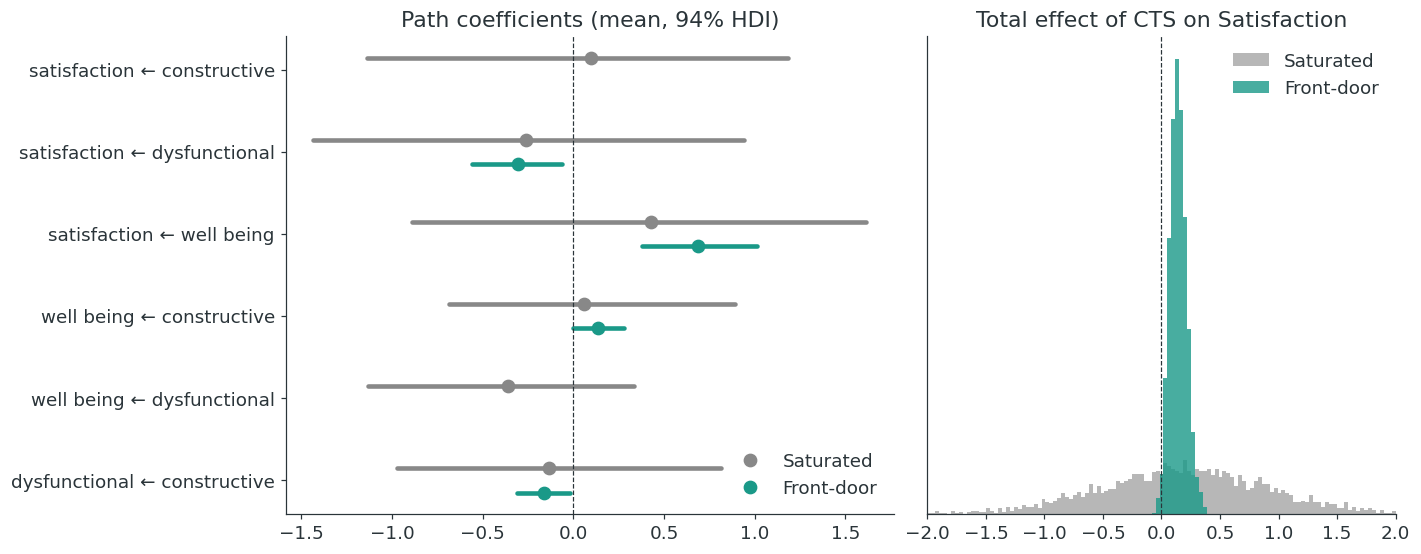

In [9]:
def path_summary(idata):
    B = idata["posterior"]["B"]
    out = {}
    for target, predictor in SATURATED_PATHS:
        draws = B.sel(latent=target, latent1=predictor).values.flatten()
        if np.allclose(draws, 0):
            continue
        lo, hi = az.hdi(draws, prob=0.94)
        out[f"{target} ← {predictor}"] = (draws.mean(), lo, hi)
    return out


fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axs[0]
paths = [f"{t} ← {p}" for t, p in SATURATED_PATHS]
for offset, (name, idata, colour) in zip(
    [0.15, -0.15], [("Saturated", idata_sat, GREY), ("Front-door", idata_fd, TEAL)]
):
    summ = path_summary(idata)
    for k, path in enumerate(paths):
        if path in summ:
            m, lo, hi = summ[path]
            ax.plot([lo, hi], [k + offset] * 2, color=colour, lw=3, solid_capstyle="round")
            ax.plot(m, k + offset, "o", color=colour, ms=8, label=name if k == 0 else None)
ax.axvline(0, color=DARK, lw=0.8, ls="--")
ax.set_yticks(range(len(paths)), paths)
ax.set_title("Path coefficients (mean, 94% HDI)")
ax.legend(frameon=False, loc="lower right")

ax = axs[1]
bins = np.linspace(-2, 2, 120)
ax.hist(total_effect_draws(idata_sat), bins=bins, color=GREY, alpha=0.6, density=True, label="Saturated")
ax.hist(total_effect_draws(idata_fd), bins=bins, color=TEAL, alpha=0.8, density=True, label="Front-door")
ax.axvline(0, color=DARK, lw=0.8, ls="--")
ax.set_xlim(-2, 2)
ax.set_yticks([])
ax.set_title("Total effect of CTS on Satisfaction")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{IMAGES}/payoff.png", dpi=150, bbox_inches="tight")

The global fit is essentially unchanged; the SRMR is about the same for both models. That is what we should expect, because the restrictions trade one-for-one for identification. But it means **fit cannot test the restrictions**. The support for the front-door estimate comes from how well the mechanism is built, not from the data's verdict on it.

The rest of the notebook asks how much of the front-door precision the restrictions themselves supply, and what happens if they are wrong.

## Sensitivity I: relaxing the zeros

Following Muthén & Asparouhov (2012), we replace the exact zeros in $B$ with small-variance priors $\text{Normal}(0, \sigma)$ and sweep $\sigma$. We run two variants:

- **direct only**: re-admit just the CTS → Satisfaction edge, the one the front-door criterion forbids;
- **both removed edges**: CTS → Satisfaction and DTS → WB.

$\Psi_\zeta$ keeps its front-door restrictions throughout. As $\sigma \to 0$ we recover the front-door model; as $\sigma$ grows, the direct edge and the free $\text{Cov}(\zeta_{CTS}, \zeta_{Sat})$ compete to explain the same covariance, and identification has to come from the prior.

In [10]:
SIGMAS = [0.01, 0.05, 0.1, 0.25, 0.5]
variants = {
    "direct only": [("satisfaction", "constructive")],
    "both removed edges": REMOVED_PATHS,
}
relax_rows = []
for variant, leak_paths in variants.items():
    for sigma in SIGMAS:
        idata_relaxed = fit(build_frontdoor(leak_sd=sigma, leak_paths=leak_paths), ppc=False)
        relax_rows.append(
            {"variant": variant, "sigma": sigma, **total_effect_summary(idata_relaxed),
             "divergences": divergences(idata_relaxed)}
        )
relax_df = pd.DataFrame(relax_rows)
relax_df["hdi_width"] = relax_df["hdi_hi"] - relax_df["hdi_lo"]
relax_df["excludes_zero"] = relax_df["hdi_lo"] > 0
relax_df.round(3)

NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, Psi_zeta_sd, Psi_zeta_rho, mu_betas, leak]
NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, Psi_zeta_sd, Psi_zeta_rho, mu_betas, leak]
NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, Psi_zeta_sd, Psi_zeta_rho, mu_betas, leak]
NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, Psi_zeta_sd, Psi_zeta_rho, mu_betas, leak]
NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, Psi_zeta_sd, Psi_zeta_rho, mu_betas, leak]
NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, Psi_zeta_sd, Psi_zeta_rho, mu_betas, leak]
NUTS[nutpie]: [lambdas1_, lambdas2_, lambdas3_, lambdas4_, Psi_cov_sd, Psi_cov_load_a, Psi_cov_load_b, Psi_zeta_sd, Psi_zeta

,variant,sigma,mean,sd,hdi_lo,hdi_hi,divergences,hdi_width,excludes_zero
0,direct only,0.01,0.143,0.072,0.020,0.283,0,0.263,True
1,direct only,0.05,0.144,0.084,-0.018,0.302,0,0.319,False
2,direct only,0.10,0.147,0.122,-0.074,0.381,0,0.454,False
3,direct only,0.25,0.146,0.247,-0.283,0.640,0,0.922,False
4,direct only,0.50,0.175,0.460,-0.719,1.040,0,1.759,False
5,both removed edges,0.01,0.144,0.071,0.014,0.273,0,0.259,True
6,both removed edges,0.05,0.145,0.083,-0.008,0.303,0,0.311,False
7,both removed edges,0.10,0.147,0.121,-0.073,0.375,0,0.447,False
8,both removed edges,0.25,0.147,0.255,-0.344,0.613,0,0.956,False
9,both removed edges,0.50,0.182,0.452,-0.656,1.030,0,1.686,False


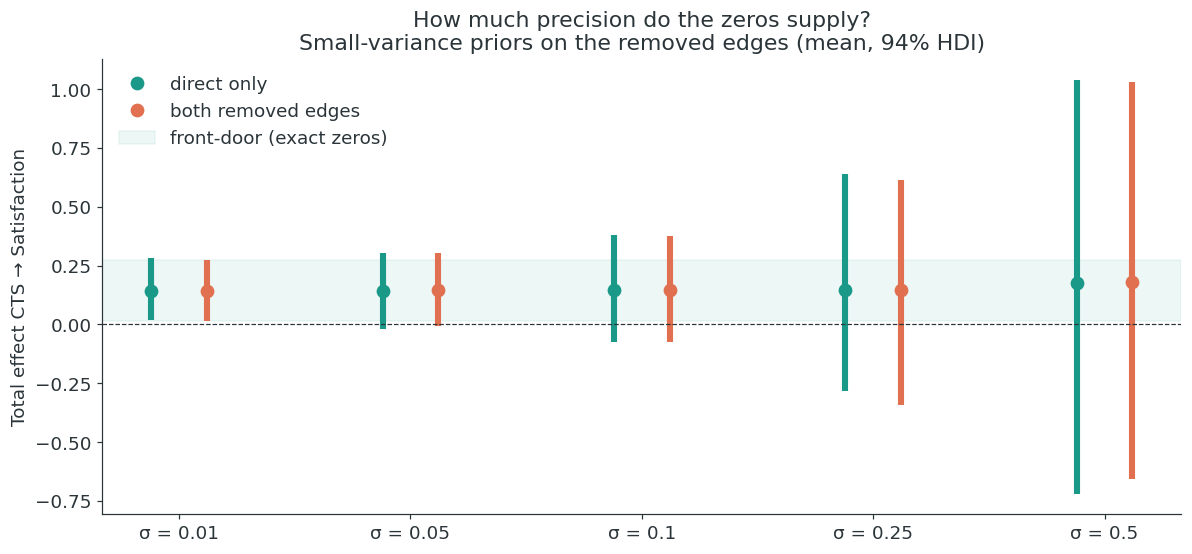

In [11]:
fig, ax = plt.subplots(figsize=(11, 5.2))
x = np.arange(len(SIGMAS))
for offset, (variant, colour) in zip([-0.12, 0.12], [(k, c) for k, c in zip(variants, [TEAL, CORAL])]):
    sub = relax_df[relax_df["variant"] == variant]
    ax.vlines(x + offset, sub["hdi_lo"], sub["hdi_hi"], color=colour, lw=4)
    ax.plot(x + offset, sub["mean"], "o", color=colour, ms=8, label=variant)

fd = headline.loc["Front-door"]
ax.axhspan(fd["hdi_lo"], fd["hdi_hi"], color=TEAL, alpha=0.08, label="front-door (exact zeros)")
ax.axhline(0, color=DARK, lw=0.8, ls="--")
ax.set_xticks(x, [f"σ = {s}" for s in SIGMAS])
ax.set_ylabel("Total effect CTS → Satisfaction")
ax.set_title("How much precision do the zeros supply?\nSmall-variance priors on the removed edges (mean, 94% HDI)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(f"{IMAGES}/precision_budget.png", dpi=150, bbox_inches="tight")

Three things stand out.

- **The point estimate barely moves.** It stays at roughly 0.14–0.18 across the sweep. The data are close to silent about the direct edge, so a prior centred on zero leaves the mean about where the exact zero put it.
- **The interval does all the moving.** Already at $\sigma = 0.05$, a prior saying the direct effect is almost surely smaller than about 0.1, the 94% HDI reaches zero. By $\sigma = 0.5$ it is nearly as wide as the saturated model's. The precision of the front-door estimate is supplied almost entirely by the exact zero on CTS → Satisfaction.
- **Re-admitting DTS → WB changes nothing.** That zero does no identifying work; the direct edge does.

This is not a failure of the method. It is the method's honest accounting: the front-door estimate is exactly as credible as the argument that nothing leaks around the mechanism.

## Sensitivity II: parameter recovery

Before asking what happens when the mechanism is wrong, we check that the front-door model can recover its own parameters at this sample size. We build a *generator* model: the front-door model with a `leak` term on the direct edge and no observed data. `pm.do` fixes every parameter at the front-door posterior means; `sample_prior_predictive` then draws a synthetic dataset of $n = 263$; and `pm.observe` conditions a fresh front-door model on it.

In [12]:
FREE_RVS = [
    "lambdas1_", "lambdas2_", "lambdas3_", "lambdas4_", "Psi_zeta_sd", "Psi_zeta_rho",
    "Psi_cov_sd", "Psi_cov_load_a", "Psi_cov_load_b", "mu_betas",
]
truth = {k: idata_fd["posterior"][k].mean(("chain", "draw")).values for k in FREE_RVS}


def simulate(delta, seed):
    # Draw a synthetic dataset from the fitted mechanism plus a direct leak of size delta.
    generator = build_frontdoor(observed=None, leak_sd=1.0, leak_paths=[("satisfaction", "constructive")])
    with pm.do(generator, {**truth, "leak": np.array([delta])}):
        prior = pm.sample_prior_predictive(
            draws=1, random_seed=seed, var_names=["likelihood", "total_effects"]
        )["prior"]
    y = prior["likelihood"].sel(chain=0, draw=0).values
    true_total = prior["total_effects"].sel(
        chain=0, draw=0, latent="satisfaction", latent1="constructive"
    ).item()
    return y, true_total


def fit_frontdoor_to(y):
    with pm.observe(build_frontdoor(observed=None), {"likelihood": y}) as inference_model:
        idata = pm.sample(**sim_kwargs)
        pm.sample_posterior_predictive(idata, extend_inferencedata=True, progressbar=False)
    return idata

In [13]:
N_RECOVERY = 8
recovery_rows = []
for rep in range(N_RECOVERY):
    y, true_total = simulate(delta=0.0, seed=SEED + rep)
    idata_rec = fit_frontdoor_to(y)
    betas = idata_rec["posterior"]["mu_betas"]
    row = {"rep": rep, "true_total": true_total, **total_effect_summary(idata_rec),
           "srmr": get_srmr(idata_rec), "divergences": divergences(idata_rec)}
    for k, path in enumerate(coords["frontdoor_paths"]):
        draws = betas.sel(frontdoor_paths=path).values.flatten()
        lo, hi = az.hdi(draws, prob=0.94)
        row[path] = (draws.mean(), lo, hi, truth["mu_betas"][k])
    recovery_rows.append(row)
recovery_df = pd.DataFrame(recovery_rows)
recovery_df["covered"] = (recovery_df["hdi_lo"] <= recovery_df["true_total"]) & (
    recovery_df["true_total"] <= recovery_df["hdi_hi"]
)
print(f"Total effect HDI covers the truth in {recovery_df['covered'].sum()} / {N_RECOVERY} replicates")
recovery_df[["rep", "true_total", "mean", "hdi_lo", "hdi_hi", "covered", "srmr", "divergences"]].round(3)

Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_

Total effect HDI covers the truth in 8 / 8 replicates


,rep,true_total,mean,hdi_lo,hdi_hi,covered,srmr,divergences
0,0,0.144,0.139,0.030,0.260,True,0.033,0
1,1,0.144,0.178,0.065,0.291,True,0.042,0
2,2,0.144,0.068,-0.044,0.197,True,0.047,0
3,3,0.144,0.165,0.019,0.328,True,0.036,0
4,4,0.144,0.099,-0.013,0.215,True,0.034,0
5,5,0.144,0.190,0.057,0.317,True,0.044,0
6,6,0.144,0.202,0.072,0.343,True,0.043,0
7,7,0.144,0.015,-0.132,0.151,True,0.044,0


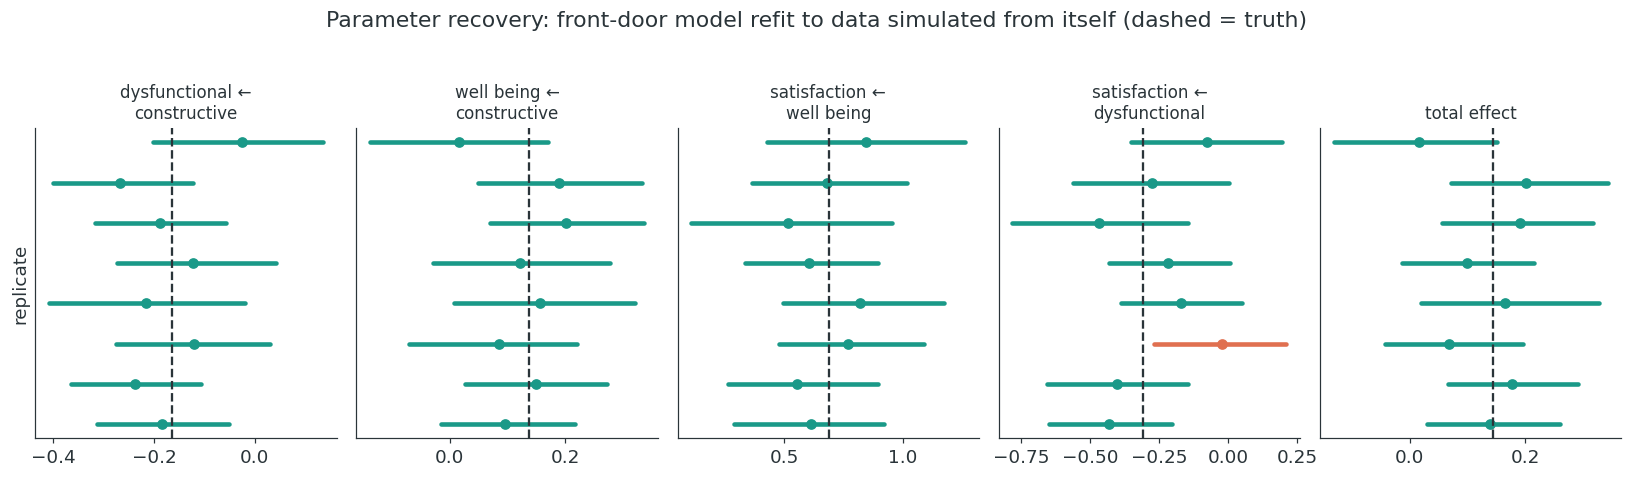

In [14]:
targets = coords["frontdoor_paths"] + ["total effect"]
fig, axs = plt.subplots(1, len(targets), figsize=(15, 4.2), sharey=True)
for ax, target in zip(axs, targets):
    for rep, row in recovery_df.iterrows():
        if target == "total effect":
            m, lo, hi, true = row["mean"], row["hdi_lo"], row["hdi_hi"], row["true_total"]
        else:
            m, lo, hi, true = row[target]
        colour = TEAL if lo <= true <= hi else CORAL
        ax.plot([lo, hi], [rep, rep], color=colour, lw=3, solid_capstyle="round")
        ax.plot(m, rep, "o", color=colour, ms=6)
    ax.axvline(true, color=DARK, lw=1.5, ls="--")
    ax.set_title(target.replace(" ~ ", " ←\n"), fontsize=11)
    ax.set_yticks([])
axs[0].set_ylabel("replicate")
fig.suptitle("Parameter recovery: front-door model refit to data simulated from itself (dashed = truth)", y=1.03)
fig.tight_layout()
fig.savefig(f"{IMAGES}/recovery.png", dpi=150, bbox_inches="tight")

When the mechanism is true, the front-door model recovers it. The 94% HDI for the total effect covers the true value in every replicate, and the path coefficients scatter around their true values.

Note the spread at $n = 263$, though: point estimates run from roughly 0.0 to 0.2 around a true 0.14. The CTS → mediator paths are small (about ±0.15), and in an unlucky sample they nearly vanish, which drags the total effect towards zero (the top replicate). The identified estimate is precise *relative to the saturated model*, not precise in absolute terms.

## Sensitivity III: a leaking mechanism

The front-door claim is that $\{DTS, WB\}$ exhausts the influence of CTS on satisfaction. Suppose it doesn't, and a direct path of size $\delta$ leaks around the mechanism. We simulate from the fitted mechanism plus the leak, then fit the (now misspecified) front-door model. The true total effect rises with $\delta$. What does the front-door model report? And does global fit notice?

In [15]:
DELTAS = [0.0, 0.1, 0.2, 0.3]
N_REPS = 5
leak_rows = []
for delta in DELTAS:
    for rep in range(N_REPS):
        y, true_total = simulate(delta=delta, seed=SEED + 100 * (1 + int(round(delta * 10))) + rep)
        idata_leak = fit_frontdoor_to(y)
        rho = idata_leak["posterior"]["Psi_zeta_rho"].sel(frontdoor_covs="satisfaction ~~ constructive")
        leak_rows.append(
            {"delta": delta, "rep": rep, "true_total": true_total, **total_effect_summary(idata_leak),
             "rho_cts_sat": float(rho.mean()), "srmr": get_srmr(idata_leak),
             "divergences": divergences(idata_leak)}
        )
leak_df = pd.DataFrame(leak_rows)
leak_df["bias"] = leak_df["mean"] - leak_df["true_total"]
leak_df["covered"] = (leak_df["hdi_lo"] <= leak_df["true_total"]) & (leak_df["true_total"] <= leak_df["hdi_hi"])
leak_summary = leak_df.groupby("delta").agg(
    true_total=("true_total", "first"), estimate=("mean", "mean"), bias=("bias", "mean"),
    coverage=("covered", "mean"), rho_cts_sat=("rho_cts_sat", "mean"), srmr=("srmr", "mean"),
)
leak_summary.round(3)

Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_rho, Psi_cov_load_b, Psi_cov_load_a, Psi_cov_sd, lambdas4_, lambdas3_, lambdas2_, lambdas1_]
Sampling: [likelihood]
Sampling: [likelihood]
NUTS[nutpie]: [mu_betas, Psi_zeta_sd, Psi_zeta_

,true_total,estimate,bias,coverage,rho_cts_sat,srmr
delta,,,,,,
0.0,0.144,0.136,-0.008,0.8,0.105,0.037
0.1,0.244,0.109,-0.135,0.4,0.177,0.038
0.2,0.344,0.235,-0.110,0.4,0.171,0.035
0.3,0.444,0.130,-0.315,0.0,0.267,0.039


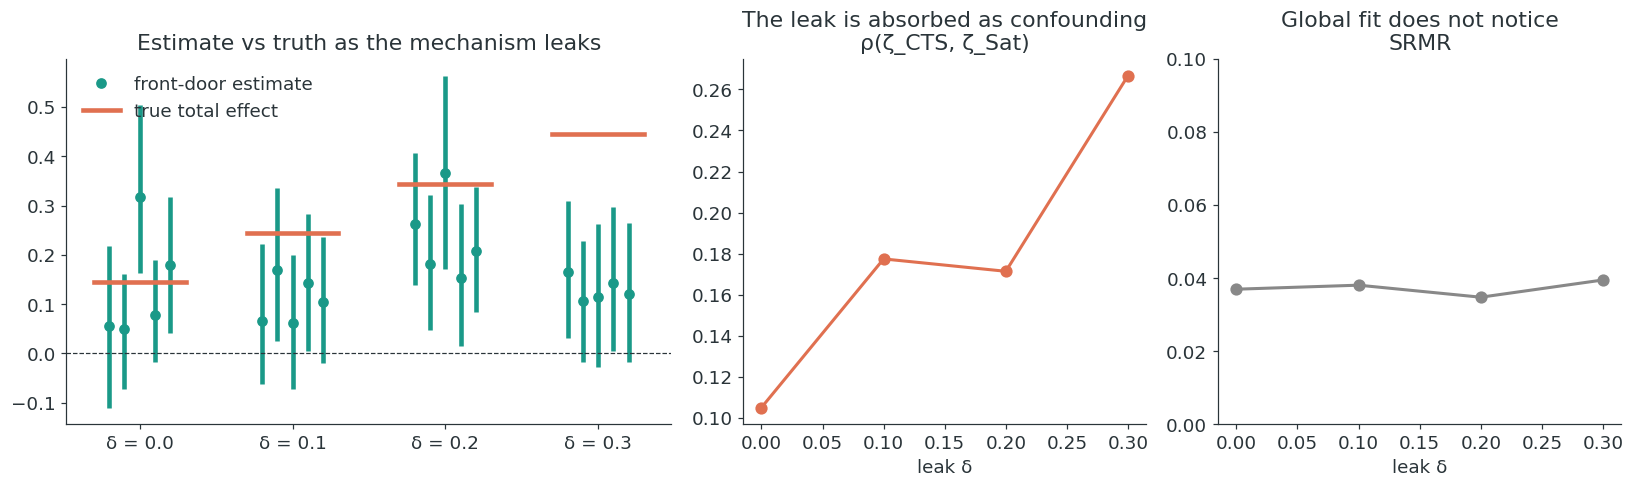

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax = axs[0]
for i, delta in enumerate(DELTAS):
    sub = leak_df[leak_df["delta"] == delta]
    xs = i + np.linspace(-0.2, 0.2, len(sub))
    ax.vlines(xs, sub["hdi_lo"], sub["hdi_hi"], color=TEAL, lw=3)
    ax.plot(xs, sub["mean"], "o", color=TEAL, ms=6, label="front-door estimate" if i == 0 else None)
    ax.plot([i - 0.3, i + 0.3], [sub["true_total"].iloc[0]] * 2, color=CORAL, lw=3,
            label="true total effect" if i == 0 else None)
ax.axhline(0, color=DARK, lw=0.8, ls="--")
ax.set_xticks(range(len(DELTAS)), [f"δ = {d}" for d in DELTAS])
ax.set_title("Estimate vs truth as the mechanism leaks")
ax.legend(frameon=False, loc="upper left")

ax = axs[1]
ax.plot(leak_summary.index, leak_summary["rho_cts_sat"], "o-", color=CORAL, lw=2, ms=7)
ax.set_xlabel("leak δ")
ax.set_title("The leak is absorbed as confounding\nρ(ζ_CTS, ζ_Sat)")

ax = axs[2]
ax.plot(leak_summary.index, leak_summary["srmr"], "o-", color=GREY, lw=2, ms=7)
ax.set_ylim(0, 0.1)
ax.set_xlabel("leak δ")
ax.set_title("Global fit does not notice\nSRMR")
fig.tight_layout()
fig.savefig(f"{IMAGES}/leak_bias.png", dpi=150, bbox_inches="tight")

This is the sharpest result in the notebook.

As the leak grows, the true total effect rises from 0.14 to 0.44, but the front-door estimate stays roughly flat between 0.1 and 0.25. Its bias reaches about −0.3 at $\delta = 0.3$, and coverage collapses.

The leak doesn't disappear. It is absorbed by the one place the design allows unexplained association between treatment and outcome: the confounding correlation $\rho(\zeta_{CTS}, \zeta_{Sat})$ climbs from about 0.10 to about 0.27. Meanwhile SRMR does not move.

A direct path around the mechanism is observationally equivalent to the confounding the design was built to tolerate, so no global fit statistic can catch it. With a positive leak, the front-door model reads part of the real effect as confounding and under-reports it.

## What the sensitivity analysis tells us

- **Precision for free in fit.** The front-door restrictions buy roughly an order of magnitude of precision and cost nothing in global fit, which is exactly why fit cannot vouch for them.
- **One zero carries it.** Almost all of that precision sits on the direct CTS → Satisfaction zero; soften it to a $\sigma = 0.05$ prior and the interval reaches zero. The front-door lower HDI bound is itself close to zero (about 0.01–0.02 across sampler settings), so "excludes zero" should be read as "just".
- **Leaks look like confounding.** If a direct path does exist, the model reads it as treatment-outcome confounding and under-reports the effect, with no warning from global fit.

So the warrant for a front-door estimate is the construction itself. Build the mechanism from constructs your theory says are exhaustive, argue for the exclusion explicitly, and report the relaxation curve alongside the point estimate, so readers can see how much of the answer the architecture supplies.

### References

- Houghton, J. D., & Jinkerson, D. L. (2007). Constructive Thought Strategies and Job Satisfaction: A Preliminary Examination. *Journal of Business and Psychology*, 22(1), 45–53.
- Kuroki, M. (2000). Selection of Post-Treatment Variables for Estimating Total Effect from Empirical Research. *Journal of the Japan Statistical Society*, 30, 129–142.
- Kuroki, M., & Cai, Z. (2004). Selection of Identifiability Criteria for Total Effects by Using Path Diagrams. *UAI 2004*, 333–340.
- Muthén, B., & Asparouhov, T. (2012). Bayesian Structural Equation Modeling: A More Flexible Representation of Substantive Theory. *Psychological Methods*, 17(3), 313–335.
- Pearl, J. (1995). Causal Diagrams for Empirical Research. *Biometrika*, 82(4), 669–688.
- Vincent, B. T., & Forde, N. (in preparation). *Bayesian Causal Inference*.

In [17]:
import sys, pytensor, nutpie
print(f"Python {sys.version.split()[0]} | PyMC {pm.__version__} | PyTensor {pytensor.__version__} | ArviZ {az.__version__} | nutpie {nutpie.__version__}")

Python 3.13.14 | PyMC 6.3.2 | PyTensor 3.3.3 | ArviZ 1.3.0 | nutpie 0.16.11
